# FIG — Gambar Latar Belakang (Proposal, Tesis, dan Presentasi)

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45) Berdasarkan Analisis Sentimen Menggunakan Metode XGBoost dan LSTM
**Penulis**: Ilda Nurida (NRP 6032251068) · **Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

> ⚠️ **Notebook ini khusus visualisasi** untuk Latar Belakang dan slide presentasi.
> **Bukan** bagian dari *pipeline* pemodelan: tidak ada output yang dipakai XGBoost/LSTM.
> Data IHSG (Cell 2) hanya untuk ilustrasi dan **tidak** termasuk variabel penelitian.

| Cell | Gambar | Data |
|---|---|---|
| 1 | Konfigurasi path & gaya | — |
| 2 | Candlestick IHSG saat isu MSCI (Jan–Feb 2026) | Yahoo Finance `^JKSE` (unduh, perlu internet) |
| 3 | Return 7 emiten energi pada 28 Jan 2026 | `harga_saham_raw.csv` |
| 4 | Ilustrasi harga → fluktuasi → volatilitas → arus berita (MEDC) | `harga_saham_raw.csv` + `skor_sentimen_harian.csv` |
| 5 | Ilustrasi indikator MACD (MEDC, Jun–Des 2023) | `harga_saham_raw.csv` |

---
## ⚙️ CELL 1 — Konfigurasi

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle, Patch

# ── SESUAIKAN PATH (None = dicari otomatis di folder proyek) ──
PATH_HARGA    = None   # contoh: r'E:\...\03_dataset\raw\harga_saham_raw.csv'
PATH_SENTIMEN = None   # contoh: r'E:\...\02_preprocessing\sentimen_indobert\output_sentimen\skor_sentimen_harian.csv'
FOLDER_OUTPUT = os.path.join('06_dokumen_tesis', 'gambar', 'latar_belakang')
BAHASA        = 'id'   # 'id' untuk naskah tesis, 'en' untuk slide bahasa Inggris

def cari_file(nama):
    for akar in ['.', '..', '../..']:
        hasil = glob.glob(os.path.join(akar, '**', nama), recursive=True)
        if hasil:
            return os.path.abspath(hasil[0])
    return None

PATH_HARGA    = PATH_HARGA or cari_file('harga_saham_raw.csv')
PATH_SENTIMEN = PATH_SENTIMEN or cari_file('skor_sentimen_harian.csv')
os.makedirs(FOLDER_OUTPUT, exist_ok=True)
print('Harga    :', PATH_HARGA)
print('Sentimen :', PATH_SENTIMEN)
print('Output   :', os.path.abspath(FOLDER_OUTPUT))
assert PATH_HARGA, 'harga_saham_raw.csv tidak ditemukan, isi PATH_HARGA secara manual.'

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
BULAN = {'id': ['', 'Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'],
         'en': ['', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']}[BAHASA]

def fmt_angka(v, desimal=0):
    s = f'{v:,.{desimal}f}'
    return s if BAHASA == 'en' else s.replace(',', 'X').replace('.', ',').replace('X', '.')

plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
                     'font.size': 10, 'axes.titlesize': 10.5,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#555',
                     'axes.grid': True, 'grid.color': '#e4e4e4', 'grid.linewidth': 0.6})

# ── Data harga 7 emiten: Adj_Close, hari tanpa transaksi (Volume = 0) dibuang ──
harga = pd.read_csv(PATH_HARGA, encoding='utf-8-sig')
harga['Date'] = pd.to_datetime(harga['Date'].astype(str).str[:10])
harga = harga[harga['Volume'] > 0].sort_values(['Emiten', 'Date']).reset_index(drop=True)
harga['Return_%'] = harga.groupby('Emiten')['Adj_Close'].transform(lambda s: np.log(s / s.shift())) * 100
harga['Vol20_%']  = harga.groupby('Emiten')['Return_%'].transform(lambda s: s.rolling(20).std())
print(f'\n✅ Harga: {len(harga):,} baris | {harga.Date.min():%d/%m/%Y} – {harga.Date.max():%d/%m/%Y}')

Harga    : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv
Sentimen : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\skor_sentimen_harian.csv
Output   : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\06_dokumen_tesis\gambar\latar_belakang

✅ Harga: 7,941 baris | 01/10/2021 – 15/07/2026


---
## 📉 CELL 2 — Candlestick IHSG saat isu MSCI
Data diunduh dari Yahoo Finance (kode `^JKSE`). `INTERVAL = '1h'` menghasilkan beberapa *candle* per hari (seperti grafik berita); `'1d'` satu *candle* per hari. Cek baris **Cek 28 Jan**: IHSG seharusnya ditutup sekitar **8.320 (−7,35%)**.

Price          Open     High      Low    Close  Return_%
Date                                                    
2026-01-22  9052.17  9109.71  8992.13  8992.18       NaN
2026-01-23  9031.49  9039.67  8837.83  8951.01     -0.46
2026-01-26  8967.73  9058.05  8923.53  8975.33      0.27
2026-01-27  8974.57  8980.23  8873.48  8980.23      0.05
2026-01-28  8393.51  8596.17  8187.73  8320.56     -7.35
2026-01-29  8027.83  8296.94  7481.99  8232.20     -1.06
2026-01-30  8308.72  8408.30  8167.16  8329.61      1.18

Cek 28 Jan 2026 → Close 8,320.56 | Return -7.35% (seharusnya ±8.320 dan −7,35%)


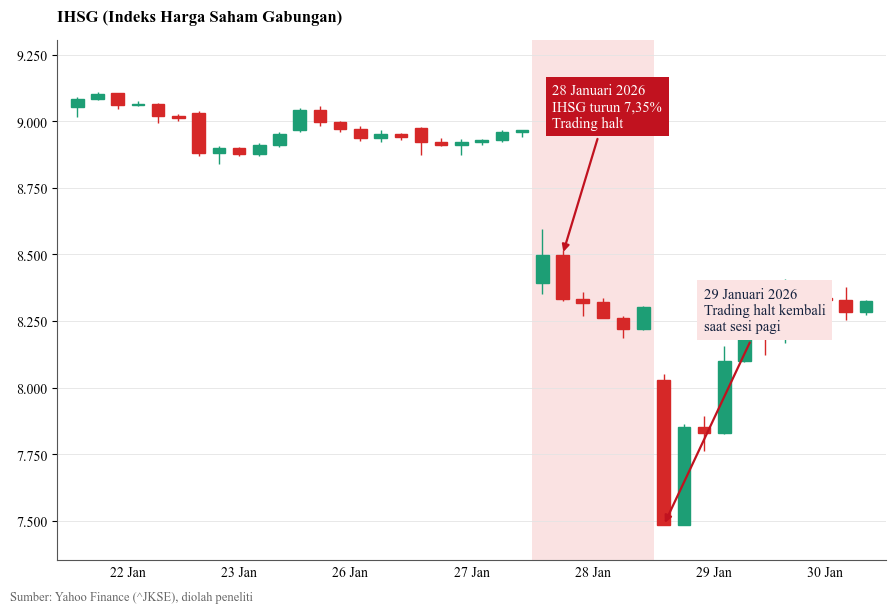

💾 06_dokumen_tesis\gambar\latar_belakang\Gambar_IHSG_MSCI_Jan2026_1h_id.png


In [2]:
# !pip install yfinance -q          # aktifkan jika yfinance belum terpasang
import yfinance as yf

AWAL, AKHIR = '2026-01-22', '2026-01-31'      # AKHIR eksklusif
INTERVAL    = '1h'                            # '1h' = per jam (seperti contoh), '1d' = per hari

def unduh(interval):
    d = yf.download('^JKSE', start=AWAL, end=AKHIR, interval=interval, auto_adjust=False, progress=False)
    if isinstance(d.columns, pd.MultiIndex):
        d.columns = d.columns.get_level_values(0)
    d = d[['Open', 'High', 'Low', 'Close']].dropna()
    idx = pd.to_datetime(d.index)
    if idx.tz is not None:
        idx = idx.tz_convert('Asia/Jakarta').tz_localize(None)    # jam WIB
    d.index = idx
    return d[d['High'] != d['Low']]                                # buang baris datar (libur/halt kosong)

harian = unduh('1d'); harian.index = harian.index.normalize()
harian['Return_%'] = harian['Close'].pct_change() * 100
ihsg = unduh(INTERVAL) if INTERVAL != '1d' else harian.copy()
if ihsg.empty:
    print('⚠️ Data per jam tidak tersedia, memakai data harian.'); ihsg = harian.copy()
print(harian.round(2).to_string())
r28 = harian.loc['2026-01-28'] if pd.Timestamp('2026-01-28') in harian.index else None
if r28 is not None:
    print(f"\nCek 28 Jan 2026 → Close {r28['Close']:,.2f} | Return {r28['Return_%']:.2f}% (seharusnya ±8.320 dan −7,35%)")

T = {'id': dict(judul='IHSG (Indeks Harga Saham Gabungan)',
                b28='28 Januari 2026\nIHSG turun {r}%\nTrading halt', b29='29 Januari 2026\nTrading halt kembali\nsaat sesi pagi',
                sumber='Sumber: Yahoo Finance (^JKSE), diolah peneliti'),
     'en': dict(judul='IHSG (Jakarta Composite Index)',
                b28='28 January 2026\nIHSG fell {r}%\nTrading halt', b29='29 January 2026\nTrading halt again\nin the morning session',
                sumber='Source: Yahoo Finance (^JKSE)')}[BAHASA]

fig, ax = plt.subplots(figsize=(9, 6))
n = len(ihsg); lebar = 0.62
for i, (tgl, r) in enumerate(ihsg.iterrows()):
    warna = '#1D9E75' if r['Close'] >= r['Open'] else '#D62828'
    ax.vlines(i, r['Low'], r['High'], color=warna, lw=1, zorder=3)
    ax.add_patch(Rectangle((i - lebar / 2, min(r['Open'], r['Close'])), lebar,
                           max(abs(r['Close'] - r['Open']), 1e-6), color=warna, zorder=3))

hari = ihsg.index.normalize()
def posisi(t):                                   # indeks candle pada tanggal t
    return np.where(hari == pd.Timestamp(t))[0]
p28, p29 = posisi('2026-01-28'), posisi('2026-01-29')
if len(p28):
    ax.axvspan(p28[0] - 0.5, p28[-1] + 0.5, color='#F8D7D7', alpha=0.7, lw=0, zorder=0)

atas, bawah = ihsg['High'].max(), ihsg['Low'].min(); rng = atas - bawah
ax.set_ylim(bawah - rng * 0.08, atas + rng * 0.12)
def candle_terdalam(pos):                        # candle dengan penurunan terbesar pada hari itu
    sub = ihsg.iloc[pos]; j = (sub['Close'] - sub['Open']).values.argmin()
    return pos[j], sub.iloc[j]
if len(p28) and r28 is not None:
    j, c = candle_terdalam(p28)
    ax.annotate(T['b28'].format(r=fmt_angka(abs(r28['Return_%']), 2)), xy=(j, c['Open']),
                xytext=(j - 0.5, atas + rng * 0.02), ha='left', va='top', fontsize=10.5, color='white',
                bbox=dict(boxstyle='square,pad=0.45', fc='#C1121F', ec='none'),
                arrowprops=dict(arrowstyle='-|>', color='#C1121F', lw=1.6))
if len(p29):
    j, c = candle_terdalam(p29)
    ax.annotate(T['b29'], xy=(j, c['Close']), xytext=(j + 2, bawah + rng * 0.55), ha='left', va='top',
                fontsize=10.5, color='#14213D', bbox=dict(boxstyle='square,pad=0.45', fc='#FBE3E3', ec='none'),
                arrowprops=dict(arrowstyle='-|>', color='#C1121F', lw=1.6))

awal_hari = [np.where(hari == d)[0][0] for d in hari.unique()]
ax.set_xticks([k + (np.sum(hari == hari[k]) - 1) / 2 for k in awal_hari])   # label di tengah tiap hari
ax.set_xticklabels([f'{hari[k].day} {BULAN[hari[k].month]}' for k in awal_hari], fontsize=10)
ax.tick_params(axis='x', length=0)
ax.set_xlim(-1, n)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_angka(v)))
ax.grid(axis='x', visible=False); ax.set_axisbelow(True)
ax.set_title(T['judul'], loc='left', fontsize=12, fontweight='bold', pad=14)
fig.text(0.01, -0.01, T['sumber'], fontsize=9, color='#666')
fig.tight_layout()
path = os.path.join(FOLDER_OUTPUT, f'Gambar_IHSG_MSCI_Jan2026_{INTERVAL}_{BAHASA}.png')
fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white'); plt.show()
print('💾', path)

---
## 📊 CELL 3 — Return 7 emiten energi pada 28 Januari 2026

,Return 28 Jan (%),Vol20 27 Jan (%),Vol20 28 Jan (%)
Emiten,,,
ADMR,-6.51,5.49,5.81
PTBA,-5.56,0.88,1.64
AKRA,-4.95,1.74,2.11
ADRO,-3.56,2.86,3.03
PGAS,-1.87,2.02,2.10
ITMG,-1.25,0.80,0.84
MEDC,-0.99,2.97,3.00


Rata-rata return 7 emiten: -3.53%


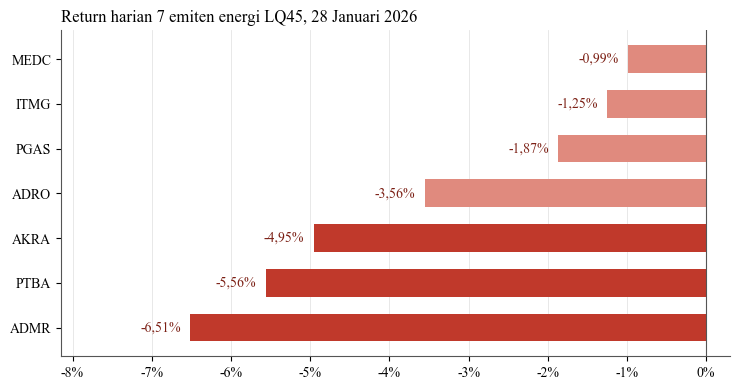

💾 06_dokumen_tesis\gambar\latar_belakang\Gambar_return_7emiten_28Jan2026_id.png


In [3]:
TGL = pd.Timestamp('2026-01-28')
r28 = (harga[harga['Date'] == TGL].set_index('Emiten')['Return_%']
       .reindex(URUTAN_EMITEN).sort_values())
v_sebelum = harga[harga['Date'] == pd.Timestamp('2026-01-27')].set_index('Emiten')['Vol20_%']
v_hari    = harga[harga['Date'] == TGL].set_index('Emiten')['Vol20_%']
tabel = pd.DataFrame({'Return 28 Jan (%)': r28.round(2),
                      'Vol20 27 Jan (%)': v_sebelum.reindex(r28.index).round(2),
                      'Vol20 28 Jan (%)': v_hari.reindex(r28.index).round(2)})
display(tabel)
print(f'Rata-rata return 7 emiten: {r28.mean():.2f}%')

judul = {'id': 'Return harian 7 emiten energi LQ45, 28 Januari 2026',
         'en': 'Daily return of 7 LQ45 energy stocks, 28 January 2026'}[BAHASA]
fig, ax = plt.subplots(figsize=(7.5, 4))
warna = ['#C0392B' if v <= -4 else '#E08A7E' for v in r28.values]
ax.barh(r28.index, r28.values, color=warna, height=0.62)
for i, v in enumerate(r28.values):
    ax.text(v - 0.12, i, f'{fmt_angka(v, 2)}%', va='center', ha='right', fontsize=10, color='#7B1F14')
ax.axvline(0, color='#555', lw=0.8)
ax.set_xlim(r28.min() * 1.25, 0.3)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{fmt_angka(v, 0)}%'))
ax.grid(axis='y', visible=False); ax.set_axisbelow(True)
ax.set_title(judul, loc='left', fontsize=12)
fig.tight_layout()
path = os.path.join(FOLDER_OUTPUT, f'Gambar_return_7emiten_28Jan2026_{BAHASA}.png')
fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white'); plt.show()
print('💾', path)

---
## 🧭 CELL 4 — Ilustrasi harga → fluktuasi → volatilitas → arus berita (MEDC)
Untuk menjawab catatan penguji: perbedaan fluktuasi dan volatilitas, serta pola volatilitas jangka panjang.

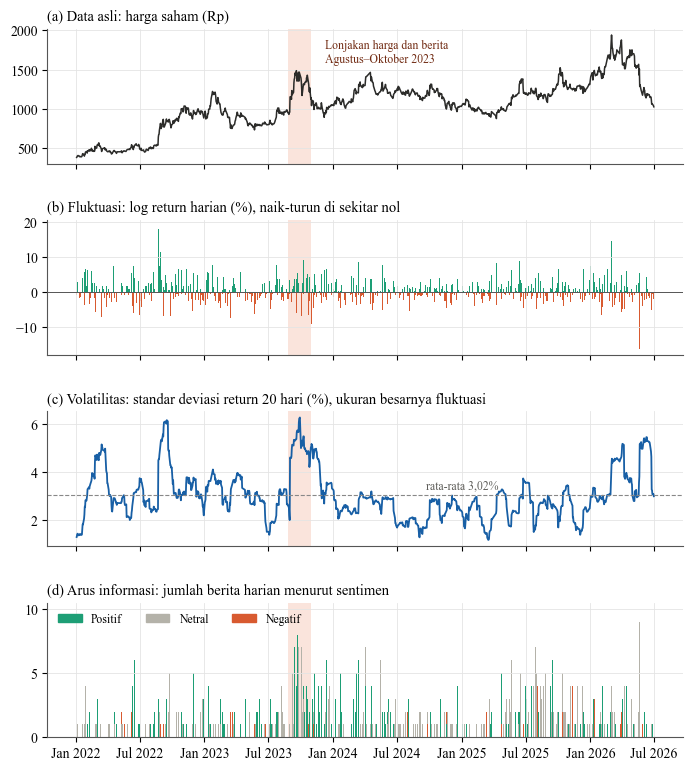

💾 06_dokumen_tesis\gambar\latar_belakang\Gambar_ilustrasi_fluktuasi_volatilitas_MEDC_id.png


In [4]:
EMITEN = 'MEDC'
EV0, EV1 = pd.Timestamp('2023-08-25'), pd.Timestamp('2023-10-31')   # periode berarsir

x = harga[(harga['Emiten'] == EMITEN) & (harga['Date'] >= '2022-01-01') & (harga['Date'] <= '2026-06-30')].copy()
if PATH_SENTIMEN:
    sh = pd.read_csv(PATH_SENTIMEN, encoding='utf-8-sig')
    sh['Date'] = pd.to_datetime(sh['Date'].astype(str).str[:10])
    x = x.merge(sh[sh['Emiten'] == EMITEN], on=['Emiten', 'Date'], how='left')
else:
    print('⚠️ skor_sentimen_harian.csv tidak ditemukan: panel (d) dilewati.')

L = {'id': ['(a) Data asli: harga saham (Rp)',
            '(b) Fluktuasi: log return harian (%), naik-turun di sekitar nol',
            '(c) Volatilitas: standar deviasi return 20 hari (%), ukuran besarnya fluktuasi',
            '(d) Arus informasi: jumlah berita harian menurut sentimen',
            'rata-rata', ['Positif', 'Netral', 'Negatif'], 'Lonjakan harga dan berita\nAgustus–Oktober 2023'],
     'en': ['(a) Raw data: stock price (IDR)',
            '(b) Fluctuation: daily log return (%), swinging around zero',
            '(c) Volatility: 20-day standard deviation of return (%), size of the swings',
            '(d) Information flow: daily news count by sentiment',
            'mean', ['Positive', 'Neutral', 'Negative'], 'Price jump and news surge\nAugust–October 2023']}[BAHASA]

n_panel = 4 if 'News_Count' in x else 3
fig, ax = plt.subplots(n_panel, 1, figsize=(8.2, 2.3 * n_panel), sharex=True, gridspec_kw={'hspace': 0.42})
for a in ax:
    a.axvspan(EV0, EV1, color='#F5C4B3', alpha=0.45, lw=0)
ax[0].plot(x['Date'], x['Adj_Close'], color='#2C2C2A', lw=1.1); ax[0].set_title(L[0], loc='left')
ax[1].bar(x['Date'], x['Return_%'], width=1.6, color=np.where(x['Return_%'] >= 0, '#1D9E75', '#D85A30'))
ax[1].axhline(0, color='#555', lw=0.7); ax[1].set_title(L[1], loc='left')
ax[2].plot(x['Date'], x['Vol20_%'], color='#185FA5', lw=1.3)
ax[2].axhline(x['Vol20_%'].mean(), color='#888', lw=0.8, ls='--')
ax[2].text(pd.Timestamp('2024-09-20'), x['Vol20_%'].mean() + 0.25, f"{L[4]} {fmt_angka(x['Vol20_%'].mean(), 2)}%",
           fontsize=8.5, color='#5F5E5A')
ax[2].set_title(L[2], loc='left')
if n_panel == 4:
    s = x['Sentiment_Mean']
    col = np.where(s >= 0.3, '#1D9E75', np.where(s <= -0.3, '#D85A30', '#B4B2A9'))
    ax[3].bar(x['Date'], x['News_Count'].fillna(0), width=1.6, color=col); ax[3].set_title(L[3], loc='left')
    ax[3].legend(handles=[Patch(color=c, label=l) for c, l in zip(['#1D9E75', '#B4B2A9', '#D85A30'], L[5])],
                 ncol=3, fontsize=8.5, frameon=False, loc='upper left')
ax[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax[-1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{BULAN[mdates.num2date(v).month]} {mdates.num2date(v).year}'))
ymax = ax[0].get_ylim()[1]
ax[0].annotate(L[6], xy=(EV1, ymax * 0.93), xytext=(EV1 + pd.Timedelta(days=40), ymax * 0.93), fontsize=8.5, color='#712B13', va='top')
path = os.path.join(FOLDER_OUTPUT, f'Gambar_ilustrasi_fluktuasi_volatilitas_{EMITEN}_{BAHASA}.png')
fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white'); plt.show()
print('💾', path)

---
## 📈 CELL 5 — Ilustrasi indikator MACD (MEDC, Juni–Desember 2023)
MACD = EMA12 − EMA26 · Sinyal = EMA9 dari MACD · Histogram = MACD − sinyal.

Bullish crossover: ['20/07/2023', '01/09/2023', '23/11/2023', '12/12/2023']
Bearish crossover: ['12/07/2023', '08/08/2023', '26/09/2023', '06/12/2023']


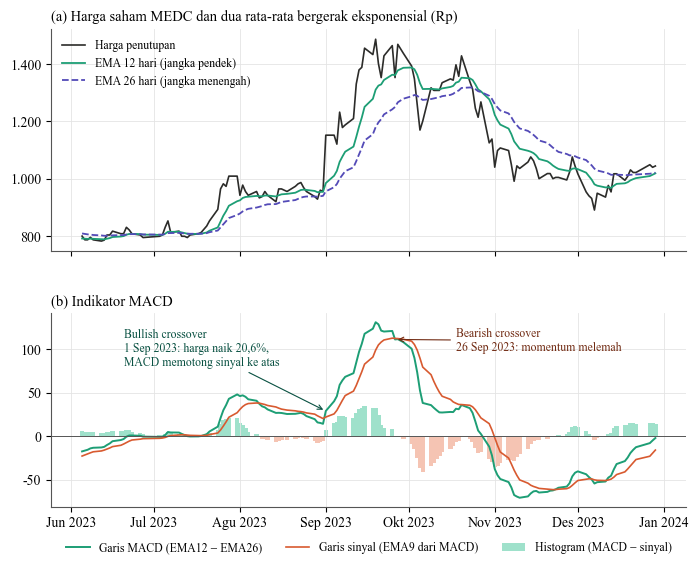

💾 06_dokumen_tesis\gambar\latar_belakang\Gambar_ilustrasi_MACD_MEDC_id.png


In [5]:
EMITEN = 'MEDC'
A0, A1 = '2023-06-01', '2023-12-29'
s = harga[harga['Emiten'] == EMITEN].set_index('Date')['Adj_Close']
e12, e26 = s.ewm(span=12, adjust=False).mean(), s.ewm(span=26, adjust=False).mean()
macd = e12 - e26; sinyal = macd.ewm(span=9, adjust=False).mean(); hist = macd - sinyal
X, E12, E26, M, S, H = [v.loc[A0:A1] for v in (s, e12, e26, macd, sinyal, hist)]
silang = np.sign(H).diff()
naik, turun = list(H.index[silang > 0]), list(H.index[silang < 0])
print('Bullish crossover:', [f'{d:%d/%m/%Y}' for d in naik])
print('Bearish crossover:', [f'{d:%d/%m/%Y}' for d in turun])

L = {'id': ['(a) Harga saham MEDC dan dua rata-rata bergerak eksponensial (Rp)', '(b) Indikator MACD',
            ['Harga penutupan', 'EMA 12 hari (jangka pendek)', 'EMA 26 hari (jangka menengah)'],
            ['Histogram (MACD − sinyal)', 'Garis MACD (EMA12 − EMA26)', 'Garis sinyal (EMA9 dari MACD)'],
            'Bullish crossover\n1 Sep 2023: harga naik 20,6%,\nMACD memotong sinyal ke atas',
            'Bearish crossover\n{d}: momentum melemah'],
     'en': ['(a) MEDC price and two exponential moving averages (IDR)', '(b) MACD indicator',
            ['Closing price', '12-day EMA (short term)', '26-day EMA (medium term)'],
            ['Histogram (MACD − signal)', 'MACD line (EMA12 − EMA26)', 'Signal line (EMA9 of MACD)'],
            'Bullish crossover\n1 Sep 2023: price up 20.6%,\nMACD crosses above signal',
            'Bearish crossover\n{d}: momentum fades']}[BAHASA]

fig, ax = plt.subplots(2, 1, figsize=(8.2, 6.2), sharex=True, gridspec_kw={'height_ratios': [1.15, 1], 'hspace': 0.3})
ax[0].plot(X.index, X, color='#2C2C2A', lw=1.2, label=L[2][0])
ax[0].plot(E12.index, E12, color='#1D9E75', lw=1.3, label=L[2][1])
ax[0].plot(E26.index, E26, color='#534AB7', lw=1.3, ls='--', label=L[2][2])
ax[0].set_title(L[0], loc='left'); ax[0].legend(frameon=False, fontsize=8.5, loc='upper left')
ax[1].bar(H.index, H, width=1.6, color=np.where(H >= 0, '#9FE1CB', '#F5C4B3'), label=L[3][0])
ax[1].plot(M.index, M, color='#1D9E75', lw=1.4, label=L[3][1])
ax[1].plot(S.index, S, color='#D85A30', lw=1.2, label=L[3][2])
ax[1].axhline(0, color='#555', lw=0.7); ax[1].set_title(L[1], loc='left')
ax[1].legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
d_up = pd.Timestamp('2023-09-01')
if d_up in M.index:
    ax[1].annotate(L[4], xy=(d_up, M.loc[d_up]), xytext=(pd.Timestamp('2023-06-20'), M.max() * 0.62),
                   fontsize=8.5, color='#085041', arrowprops=dict(arrowstyle='->', color='#085041', lw=0.8))
setelah = [d for d in turun if d > pd.Timestamp('2023-09-10')]
if setelah:
    d_dn = setelah[0]
    ax[1].annotate(L[5].format(d=f'{d_dn.day} {BULAN[d_dn.month]} {d_dn.year}'), xy=(d_dn, M.loc[d_dn]),
                   xytext=(d_dn + pd.Timedelta(days=22), M.max() * 0.75),
                   fontsize=8.5, color='#712B13', arrowprops=dict(arrowstyle='->', color='#712B13', lw=0.8))
ax[1].xaxis.set_major_locator(mdates.MonthLocator())
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{BULAN[mdates.num2date(v).month]} {mdates.num2date(v).year}'))
for a in ax:
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_angka(v)))
path = os.path.join(FOLDER_OUTPUT, f'Gambar_ilustrasi_MACD_{EMITEN}_{BAHASA}.png')
fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white'); plt.show()
print('💾', path)